In [ ]:
!pip install -q PyPDF2 python-docx nltk scikit-learn pandas numpy matplotlib seaborn

In [ ]:
import os
import re
import numpy as np
import pandas as pd

from PyPDF2 import PdfReader

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import nltk

nltk.download("stopwords")
nltk.download("punkt")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

In [ ]:
skills = [

    # =========================
    # PROGRAMMING
    # =========================
    "python",
    "java",
    "c",
    "c++",
    "c#",
    "javascript",
    "typescript",
    "go",
    "rust",
    "kotlin",
    "swift",
    "php",
    "ruby",

    # =========================
    # WEB DEVELOPMENT
    # =========================
    "html",
    "css",
    "bootstrap",
    "tailwind",
    "react",
    "angular",
    "vue",
    "next.js",
    "node.js",
    "express",
    "django",
    "flask",
    "spring",
    "spring boot",
    "rest api",
    "graphql",

    # =========================
    # DATABASE
    # =========================
    "sql",
    "mysql",
    "postgresql",
    "oracle",
    "mongodb",
    "redis",
    "firebase",
    "sqlite",
    "database design",
    "database management",

    # =========================
    # DATA SCIENCE
    # =========================
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scipy",
    "statistics",
    "data analysis",
    "data visualization",
    "excel",
    "power bi",
    "tableau",

    # =========================
    # MACHINE LEARNING / AI
    # =========================
    "machine learning",
    "deep learning",
    "artificial intelligence",
    "data science",
    "natural language processing",
    "nlp",
    "computer vision",
    "tensorflow",
    "pytorch",
    "scikit-learn",
    "keras",
    "opencv",
    "transformers",
    "bert",
    "llm",
    "generative ai",
    "prompt engineering",

    # =========================
    # DSA / CS
    # =========================
    "data structures",
    "algorithms",
    "object oriented programming",
    "oops",
    "dbms",
    "operating systems",
    "computer networks",
    "software engineering",

    # =========================
    # CLOUD
    # =========================
    "aws",
    "azure",
    "google cloud",
    "cloud computing",
    "amazon ec2",
    "amazon s3",
    "lambda",

    # =========================
    # DEVOPS
    # =========================
    "git",
    "github",
    "gitlab",
    "docker",
    "kubernetes",
    "jenkins",
    "ci/cd",
    "terraform",
    "ansible",
    "linux",

    # =========================
    # CYBERSECURITY
    # =========================
    "cybersecurity",
    "network security",
    "ethical hacking",
    "penetration testing",
    "cryptography",
    "firewalls",
    "wireshark",
    "siem",

    # =========================
    # MOBILE
    # =========================
    "android",
    "android studio",
    "flutter",
    "dart",
    "ios",
    "swift ui",
    "react native",

    # =========================
    # TESTING
    # =========================
    "software testing",
    "manual testing",
    "automation testing",
    "selenium",
    "cypress",
    "postman",
    "junit",
    "pytest",

    # =========================
    # DESIGN
    # =========================
    "ui design",
    "ux design",
    "figma",
    "adobe xd",
    "photoshop",

    # =========================
    # BUSINESS
    # =========================
    "business analysis",
    "business intelligence",
    "product management",
    "project management",
    "agile",
    "scrum",
    "jira",

    # =========================
    # SOFT SKILLS
    # =========================
    "communication",
    "leadership",
    "problem solving",
    "teamwork",
    "time management",
    "critical thinking"
]

In [ ]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

def clean_text(text):
    text = text.lower()

    # Remove special characters
    text = re.sub(r'[^a-zA-Z0-9+#.\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text)

    # Remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

In [ ]:
sample = """
I am a Computer Science student with experience in
Python, Java, SQL, Machine Learning and Data Structures.
"""

print(clean_text(sample))

computer science student experience python java sql machine learning data structures.


In [ ]:
def extract_skills(text):
    text = text.lower()

    found_skills = []

    for skill in skills:
        if skill.lower() in text:
            found_skills.append(skill)

    return sorted(set(found_skills))

In [ ]:
resume_text = """
Computer Science student skilled in Python, Java,
SQL, Machine Learning, Data Structures, Git and GitHub.
"""

print(extract_skills(resume_text))

['c', 'data structures', 'git', 'github', 'java', 'machine learning', 'python', 'sql']


In [ ]:
jobs = {

    # =========================
    # SOFTWARE DEVELOPMENT
    # =========================

    "Software Developer": """
    Software Developer required with Python, Java,
    Data Structures, Algorithms, OOP, SQL, Git,
    GitHub and problem solving.
    """,

    "Frontend Developer": """
    Frontend Developer required with HTML, CSS,
    JavaScript, React, TypeScript, Bootstrap,
    Git and UI design.
    """,

    "Backend Developer": """
    Backend Developer required with Python, Java,
    Node.js, Express, SQL, MongoDB, REST API,
    Docker and Git.
    """,

    "Full Stack Developer": """
    Full Stack Developer required with HTML, CSS,
    JavaScript, React, Node.js, Express, SQL,
    MongoDB, REST API and Git.
    """,

    # =========================
    # AI / ML
    # =========================

    "Machine Learning Engineer": """
    Machine Learning Engineer required with Python,
    Machine Learning, Deep Learning, NumPy, Pandas,
    Scikit-learn, TensorFlow, PyTorch, SQL and Git.
    """,

    "Data Scientist": """
    Data Scientist required with Python, Statistics,
    Machine Learning, Pandas, NumPy, Matplotlib,
    Scikit-learn, SQL and Data Visualization.
    """,

    "AI Engineer": """
    AI Engineer required with Python, Artificial Intelligence,
    Machine Learning, Deep Learning, TensorFlow,
    PyTorch, NLP, Computer Vision and Generative AI.
    """,

    "NLP Engineer": """
    NLP Engineer required with Python, NLP,
    Natural Language Processing, Transformers,
    BERT, Machine Learning, Deep Learning,
    PyTorch and TensorFlow.
    """,

    # =========================
    # DATA
    # =========================

    "Data Analyst": """
    Data Analyst required with Python, SQL,
    Pandas, NumPy, Excel, Statistics,
    Data Analysis, Power BI and Data Visualization.
    """,

    "Data Engineer": """
    Data Engineer required with Python, SQL,
    Data Engineering, Database Management,
    AWS, Docker, Linux and Data Processing.
    """,

    "Business Intelligence Analyst": """
    BI Analyst required with SQL, Power BI,
    Tableau, Excel, Data Visualization,
    Statistics and Business Intelligence.
    """,

    # =========================
    # CLOUD / DEVOPS
    # =========================

    "Cloud Engineer": """
    Cloud Engineer required with AWS, Azure,
    Cloud Computing, Linux, Docker, Kubernetes,
    Terraform and Git.
    """,

    "DevOps Engineer": """
    DevOps Engineer required with Linux, Git,
    Docker, Kubernetes, Jenkins, CI/CD,
    AWS, Terraform and Ansible.
    """,

    "AWS Cloud Engineer": """
    AWS Cloud Engineer required with AWS,
    Amazon EC2, Amazon S3, Lambda, Docker,
    Linux, Terraform and Cloud Computing.
    """,

    # =========================
    # CYBERSECURITY
    # =========================

    "Cybersecurity Analyst": """
    Cybersecurity Analyst required with Cybersecurity,
    Network Security, Firewalls, SIEM, Wireshark,
    Linux, Cryptography and Security Monitoring.
    """,

    "Ethical Hacker": """
    Ethical Hacker required with Ethical Hacking,
    Penetration Testing, Network Security,
    Linux, Cryptography, Wireshark and Cybersecurity.
    """,

    # =========================
    # NETWORKING
    # =========================

    "Network Engineer": """
    Network Engineer required with Computer Networks,
    Network Security, Linux, Wireshark, Firewalls,
    TCP/IP and Network Administration.
    """,

    "System Administrator": """
    System Administrator required with Linux,
    Windows Server, Networking, Computer Networks,
    Cybersecurity, Shell Scripting and Cloud Computing.
    """,

    # =========================
    # MOBILE
    # =========================

    "Android Developer": """
    Android Developer required with Java, Kotlin,
    Android Studio, Firebase, SQL, Git and REST API.
    """,

    "Flutter Developer": """
    Flutter Developer required with Flutter,
    Dart, Firebase, REST API, Git, UI Design
    and Mobile Development.
    """,

    # =========================
    # TESTING
    # =========================

    "QA Engineer": """
    QA Engineer required with Software Testing,
    Manual Testing, Automation Testing, Selenium,
    Postman, JUnit, Python and Git.
    """,

    "Automation Tester": """
    Automation Tester required with Selenium,
    Cypress, Python, Java, Pytest, JUnit,
    Postman and Software Testing.
    """,

    # =========================
    # UI / UX
    # =========================

    "UI UX Designer": """
    UI UX Designer required with UI Design,
    UX Design, Figma, Adobe XD, Photoshop,
    Prototyping and User Research.
    """,

    # =========================
    # BUSINESS
    # =========================

    "Business Analyst": """
    Business Analyst required with Business Analysis,
    Excel, SQL, Power BI, Communication,
    Problem Solving, Agile and Jira.
    """,

    "Product Manager": """
    Product Manager required with Product Management,
    Agile, Scrum, Jira, Communication,
    Leadership, Problem Solving and Data Analysis.
    """
}

In [ ]:
def calculate_similarity(resume, job_description):

    documents = [
        clean_text(resume),
        clean_text(job_description)
    ]

    vectorizer = TfidfVectorizer()

    tfidf_matrix = vectorizer.fit_transform(documents)

    similarity = cosine_similarity(
        tfidf_matrix[0:1],
        tfidf_matrix[1:2]
    )[0][0]

    return similarity * 100

In [ ]:
resume = """
Computer Science student with strong knowledge of
Python, Java, SQL, Data Structures, Algorithms,
Machine Learning, Pandas, NumPy, Git and GitHub.
"""

results = []

for job, description in jobs.items():

    score = calculate_similarity(
        resume,
        description
    )

    results.append({
        "Job": job,
        "Match Score (%)": round(score, 2)
    })

results_df = pd.DataFrame(results)

results_df

,Job,Match Score (%)
0,Software Developer,35.36
1,Frontend Developer,3.67
2,Backend Developer,15.07
3,Full Stack Developer,6.53
4,Machine Learning Engineer,34.27
5,Data Scientist,31.69
6,AI Engineer,15.59
7,NLP Engineer,12.45
8,Data Analyst,24.35
9,Data Engineer,16.83


In [ ]:
resume_skills = set(extract_skills(resume))

print("Resume Skills:")
print(sorted(resume_skills))

Resume Skills:
['algorithms', 'c', 'data structures', 'git', 'github', 'go', 'java', 'machine learning', 'numpy', 'pandas', 'python', 'sql']


In [ ]:
job_name = "Machine Learning Engineer"

required_skills = set(
    extract_skills(jobs[job_name])
)

matched_skills = resume_skills.intersection(required_skills)

missing_skills = required_skills - resume_skills

print("Job:", job_name)

print("\nMatched Skills:")
print(sorted(matched_skills))

print("\nMissing Skills:")
print(sorted(missing_skills))

Job: Machine Learning Engineer

Matched Skills:
['c', 'git', 'machine learning', 'numpy', 'pandas', 'python', 'sql']

Missing Skills:
['deep learning', 'pytorch', 'scikit-learn', 'tensorflow']


In [ ]:
from google.colab import files

uploaded = files.upload()

resume_file = list(uploaded.keys())[0]

print("Uploaded:", resume_file)

Saving Jay_Bhakat_Resume.pdf to Jay_Bhakat_Resume.pdf
Uploaded: Jay_Bhakat_Resume.pdf


In [ ]:
from PyPDF2 import PdfReader

def extract_pdf_text(file_path):
    reader = PdfReader(file_path)

    text = ""

    for page in reader.pages:
        page_text = page.extract_text()

        if page_text:
            text += page_text + "\n"

    return text

In [ ]:
resume_text = extract_pdf_text(resume_file)

print(resume_text[:3000])

Jay Bhakat
+91 9508611898 |bhakatjay.work@gmail.com |jay-bhakat07 |jaybhakat07
Professional Summary
Pre-final year B.Tech Computer Science (Data Science) student with a strong foundation in data analytics, built through
independent, end-to-end projects rather than formal work experience. Proficient in Python (pandas, SQLAlchemy), SQL
Server, and Power BI, with hands-on experience designing data pipelines, integrating databases, and building automated
dashboards and reports. Demonstrated ability to self-learn and deliver complete analytics workflows – from raw data
collection via APIs to polished, presentation-ready insights. Seeking an internship/entry-level opportunity to apply strong
technical fundamentals and a builder’s mindset to real-world data problems.
Education
Chandigarh Engineering College Mohali, Punjab
Bachelor of Technology in Computer Science (Data Science) CGPA: 7.7/10 2024 – Expected July 2028
Senior Secondary (12th)
Percentage: 62.5% 2022
Secondary (10th)
Percentage: 

In [ ]:
resume_skills = extract_skills(resume_text)

print("Detected Skills:")
for skill in resume_skills:
    print("✓", skill)

Detected Skills:
✓ c
✓ css
✓ data science
✓ express
✓ git
✓ go
✓ next.js
✓ node.js
✓ numpy
✓ pandas
✓ power bi
✓ python
✓ sql
✓ tailwind
✓ typescript


In [ ]:
analysis = []

for job_name, job_description in jobs.items():

    score = calculate_similarity(
        resume_text,
        job_description
    )

    required_skills = set(
        extract_skills(job_description)
    )

    candidate_skills = set(
        extract_skills(resume_text)
    )

    matched = candidate_skills.intersection(required_skills)
    missing = required_skills - candidate_skills

    analysis.append({
        "Job": job_name,
        "Match Score": round(score, 2),
        "Matched Skills": ", ".join(sorted(matched)),
        "Missing Skills": ", ".join(sorted(missing))
    })

analysis_df = pd.DataFrame(analysis)

analysis_df

,Job,Match Score,Matched Skills,Missing Skills
0,Software Developer,12.34,"c, git, go, python, sql","algorithms, data structures, github, java, pro..."
1,Frontend Developer,2.02,"c, css, git, typescript","bootstrap, html, java, javascript, react, ui d..."
2,Backend Developer,12.38,"c, express, git, go, node.js, python, sql","docker, java, mongodb, rest api"
3,Full Stack Developer,9.20,"c, css, express, git, go, node.js, sql","html, java, javascript, mongodb, react, rest api"
4,Machine Learning Engineer,5.52,"c, git, numpy, pandas, python, sql","deep learning, machine learning, pytorch, scik..."
5,Data Scientist,21.84,"c, numpy, pandas, python, sql","data visualization, machine learning, matplotl..."
6,AI Engineer,3.02,"c, python","artificial intelligence, computer vision, deep..."
7,NLP Engineer,1.45,"c, python","bert, deep learning, machine learning, natural..."
8,Data Analyst,36.73,"c, numpy, pandas, power bi, python, sql","data analysis, data visualization, excel, stat..."
9,Data Engineer,26.50,"c, python, sql","aws, database management, docker, linux"


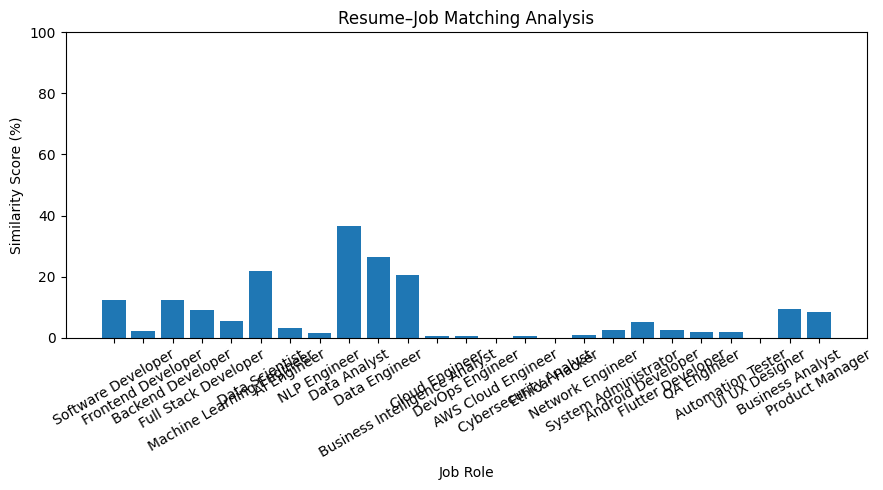

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    analysis_df["Job"],
    analysis_df["Match Score"]
)

plt.xlabel("Job Role")
plt.ylabel("Similarity Score (%)")
plt.title("Resume–Job Matching Analysis")

plt.xticks(rotation=30)
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [ ]:
def analyze_resume_for_job(resume_text, job_name):

    job_description = jobs[job_name]

    score = calculate_similarity(
        resume_text,
        job_description
    )

    resume_skills = set(
        extract_skills(resume_text)
    )

    required_skills = set(
        extract_skills(job_description)
    )

    matched = resume_skills & required_skills
    missing = required_skills - resume_skills

    print("=" * 50)
    print("RESUME ANALYSIS")
    print("=" * 50)

    print("\nJob:", job_name)

    print(
        f"\nSimilarity Score: {score:.2f}%"
    )

    print("\nMatched Skills:")
    for skill in sorted(matched):
        print("✓", skill)

    print("\nMissing Skills:")
    for skill in sorted(missing):
        print("✗", skill)

    print("=" * 50)

In [ ]:
analyze_resume_for_job(
    resume_text,
    "Machine Learning Engineer"
)

RESUME ANALYSIS

Job: Machine Learning Engineer

Similarity Score: 5.52%

Matched Skills:
✓ c
✓ git
✓ numpy
✓ pandas
✓ python
✓ sql

Missing Skills:
✗ deep learning
✗ machine learning
✗ pytorch
✗ scikit-learn
✗ tensorflow


In [ ]:
def extract_skills(text):
    text = text.lower()

    found_skills = []

    for skill in skills:
        skill_lower = skill.lower()

        # Exact word/phrase matching
        pattern = r'(?<!\w)' + re.escape(skill_lower) + r'(?!\w)'

        if re.search(pattern, text):
            found_skills.append(skill)

    return sorted(set(found_skills))

In [ ]:
def calculate_match_score(resume, job_description):

    # -----------------------------
    # 1. TF-IDF similarity
    # -----------------------------
    documents = [
        clean_text(resume),
        clean_text(job_description)
    ]

    vectorizer = TfidfVectorizer()

    tfidf_matrix = vectorizer.fit_transform(documents)

    similarity = cosine_similarity(
        tfidf_matrix[0:1],
        tfidf_matrix[1:2]
    )[0][0]

    tfidf_score = similarity * 100

    # -----------------------------
    # 2. Skill similarity
    # -----------------------------
    resume_skills = set(extract_skills(resume))
    job_skills = set(extract_skills(job_description))

    if len(job_skills) > 0:
        skill_score = (
            len(resume_skills.intersection(job_skills))
            / len(job_skills)
        ) * 100
    else:
        skill_score = 0

    # -----------------------------
    # 3. Combined score
    # -----------------------------
    final_score = (
        0.4 * tfidf_score +
        0.6 * skill_score
    )

    return round(final_score, 2)

In [ ]:
analysis = []

for job_name, job_description in jobs.items():

    score = calculate_match_score(
        resume_text,
        job_description
    )

    candidate_skills = set(
        extract_skills(resume_text)
    )

    required_skills = set(
        extract_skills(job_description)
    )

    matched = candidate_skills.intersection(
        required_skills
    )

    missing = required_skills - candidate_skills

    analysis.append({
        "Job": job_name,
        "Match Score (%)": score,
        "Matched Skills": ", ".join(sorted(matched)),
        "Missing Skills": ", ".join(sorted(missing))
    })

analysis_df = pd.DataFrame(analysis)

analysis_df

,Job,Match Score (%),Matched Skills,Missing Skills
0,Software Developer,27.43,"git, python, sql","algorithms, data structures, github, java, pro..."
1,Frontend Developer,23.31,"css, git, typescript","bootstrap, html, javascript, react, ui design"
2,Backend Developer,38.28,"express, git, node.js, python, sql","docker, java, mongodb, rest api"
3,Full Stack Developer,33.68,"css, express, git, node.js, sql","html, javascript, mongodb, react, rest api"
4,Machine Learning Engineer,32.21,"git, numpy, pandas, python, sql","deep learning, machine learning, pytorch, scik..."
5,Data Scientist,35.40,"numpy, pandas, python, sql","data visualization, machine learning, matplotl..."
6,AI Engineer,7.87,python,"artificial intelligence, computer vision, deep..."
7,NLP Engineer,7.25,python,"bert, deep learning, machine learning, natural..."
8,Data Analyst,48.02,"numpy, pandas, power bi, python, sql","data analysis, data visualization, excel, stat..."
9,Data Engineer,30.60,"python, sql","aws, database management, docker, linux"


In [ ]:
print("RESUME SKILLS")
print("=" * 30)

for skill in extract_skills(resume_text):
    print("✓", skill)

RESUME SKILLS
✓ css
✓ data science
✓ express
✓ git
✓ next.js
✓ node.js
✓ numpy
✓ pandas
✓ power bi
✓ python
✓ sql
✓ tailwind
✓ typescript


In [ ]:
print("\nJOB SKILLS")
print("=" * 30)

for skill in extract_skills(jobs["Machine Learning Engineer"]):
    print("✓", skill)


JOB SKILLS
✓ deep learning
✓ git
✓ machine learning
✓ numpy
✓ pandas
✓ python
✓ pytorch
✓ scikit-learn
✓ sql
✓ tensorflow


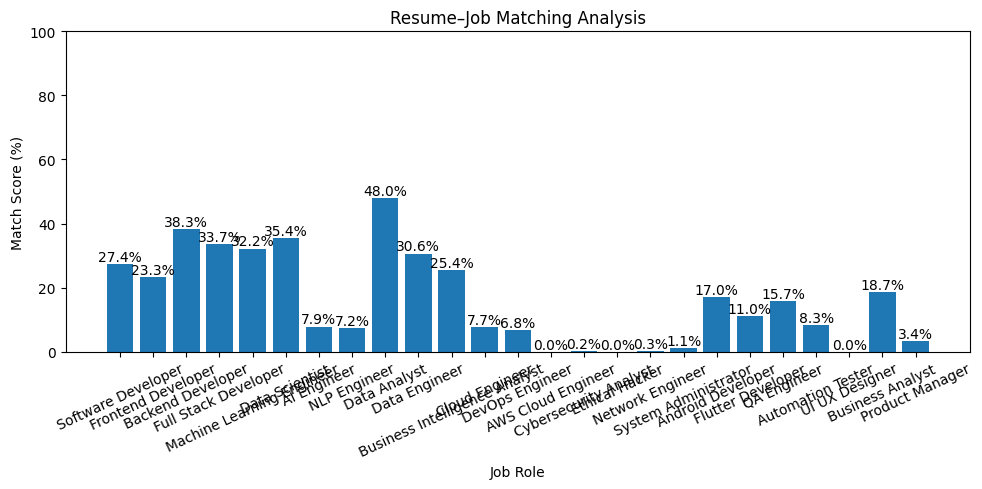

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

bars = plt.bar(
    analysis_df["Job"],
    analysis_df["Match Score (%)"]
)

plt.title("Resume–Job Matching Analysis")
plt.xlabel("Job Role")
plt.ylabel("Match Score (%)")

plt.ylim(0, 100)

plt.xticks(rotation=25)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 1,
        f"{height:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [ ]:
!pip install -q streamlit pyngrok

In [ ]:
%%writefile app.py
import streamlit as st
import re
import pandas as pd
from PyPDF2 import PdfReader
from docx import Document
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


# =========================================================
# PAGE CONFIGURATION
# =========================================================

st.set_page_config(
    page_title="ResumeAI",
    page_icon="📄",
    layout="wide",
    initial_sidebar_state="expanded",
)


# =========================================================
# SESSION STATE
# =========================================================

if "analysis" not in st.session_state:
    st.session_state["analysis"] = None

if "resume_text" not in st.session_state:
    st.session_state["resume_text"] = ""

if "resume_name" not in st.session_state:
    st.session_state["resume_name"] = ""


# =========================================================
# CUSTOM CSS
# =========================================================

st.markdown(
    """
    <style>
    :root {
        --bg: #080d18;
        --panel: #111a2b;
        --panel-soft: #151f33;
        --border: #26344b;
        --muted: #9aa9bd;
        --text: #edf3fb;
        --accent: #7c8cff;
        --accent2: #45c7b8;
    }

    .stApp {
        background:
            radial-gradient(circle at 12% 0%, rgba(87, 105, 255, .13), transparent 28rem),
            radial-gradient(circle at 90% 8%, rgba(69, 199, 184, .08), transparent 25rem),
            var(--bg);
        color: var(--text);
    }

    .block-container {
        max-width: 1440px;
        padding: 2rem 2.2rem 4rem;
    }

    section[data-testid="stSidebar"] {
        background: #0d1524;
        border-right: 1px solid var(--border);
    }

    section[data-testid="stSidebar"] > div {
        padding-top: 1.5rem;
    }

    h1, h2, h3 {
        color: var(--text) !important;
        letter-spacing: -0.035em;
    }

    h1 { font-size: clamp(2rem, 4vw, 3rem) !important; font-weight: 800 !important; }
    h2 { font-size: 1.65rem !important; font-weight: 750 !important; }
    h3 { font-size: 1.12rem !important; font-weight: 700 !important; }

    p, label, [data-testid="stMarkdownContainer"] {
        color: #d5deeb;
    }

    .hero {
        padding: 1.6rem 1.8rem;
        border: 1px solid var(--border);
        border-radius: 22px;
        background: linear-gradient(120deg, rgba(30, 43, 70, .96), rgba(17, 26, 43, .92));
        margin-bottom: 1.5rem;
        box-shadow: 0 18px 55px rgba(0,0,0,.18);
    }

    .eyebrow {
        color: #9eacff;
        text-transform: uppercase;
        letter-spacing: .16em;
        font-size: .72rem;
        font-weight: 800;
        margin-bottom: .5rem;
    }

    .hero-subtitle { color: #aebbd0; font-size: 1rem; margin-top: .25rem; }

    .section-kicker {
        color: #91a3bd;
        text-transform: uppercase;
        letter-spacing: .12em;
        font-size: .72rem;
        font-weight: 800;
        margin-bottom: .3rem;
    }

    [data-testid="stMetric"] {
        background: linear-gradient(145deg, #151f33, #101827);
        border: 1px solid var(--border);
        border-radius: 18px;
        padding: 1.1rem 1.2rem;
        box-shadow: 0 10px 30px rgba(0,0,0,.12);
    }

    [data-testid="stMetricLabel"] { color: #aab8cc !important; }
    [data-testid="stMetricValue"] { color: #f4f7fc !important; font-weight: 800; }

    [data-testid="stFileUploader"] {
        background: rgba(17, 26, 43, .8);
        border: 1px dashed #526486;
        border-radius: 18px;
        padding: 1rem;
    }

    [data-testid="stFileUploader"] section {
        background: transparent;
    }

    .stButton > button, .stDownloadButton > button {
        border-radius: 12px;
        min-height: 2.8rem;
        font-weight: 750;
        border: 1px solid rgba(124, 140, 255, .45);
        transition: all .2s ease;
    }

    .stButton > button[kind="primary"] {
        background: linear-gradient(100deg, #6878f5, #8a70ed);
        color: white;
        border: 0;
        box-shadow: 0 8px 24px rgba(104, 120, 245, .25);
    }

    .stButton > button:hover, .stDownloadButton > button:hover {
        transform: translateY(-1px);
        border-color: #9aa5ff;
    }

    div[data-testid="stAlert"] { border-radius: 12px; }
     div[data-testid="stDataFrame"] {
        border: 1px solid var(--border);
        border-radius: 14px;
        overflow: hidden;
    }

    .skill-chip {
        display: inline-block;
        padding: .42rem .72rem;
        margin: .2rem .25rem .2rem 0;
        border-radius: 999px;
        font-size: .84rem;
        font-weight: 650;
        border: 1px solid;
    }

    .skill-good {
        color: #83e2c1;
        background: rgba(50, 190, 145, .10);
        border-color: rgba(83, 211, 166, .28);
    }

    .skill-missing {
        color: #ffbdad;
        background: rgba(239, 105, 105, .09);
        border-color: rgba(239, 125, 125, .28);
    }

    .job-card {
        background: linear-gradient(145deg, #151f33, #101827);
        border: 1px solid var(--border);
        border-radius: 16px;
        padding: 1rem 1.1rem;
        margin-bottom: .8rem;
    }

    .small-muted { color: #98a8bf; font-size: .86rem; }
    hr { border-color: var(--border) !important; }

    @media (max-width: 800px) {
        .block-container { padding: 1.2rem 1rem 3rem; }
        .hero { padding: 1.2rem; }
    }
    </style>
    """,
    unsafe_allow_html=True,
)
# =========================================================
# SKILLS DATABASE
# =========================================================

skills = [
    "python", "java", "c", "c++", "c#", "javascript", "typescript",
    "go", "rust", "kotlin", "swift", "php", "ruby",

    "html", "css", "bootstrap", "tailwind", "react", "angular", "vue",
    "next.js", "node.js", "express", "django", "flask", "spring",
    "spring boot", "rest api", "graphql",

    "sql", "mysql", "postgresql", "oracle", "mongodb", "redis",
    "firebase", "sqlite", "database design", "database management",

    "pandas", "numpy", "matplotlib", "seaborn", "scipy", "statistics",
    "data analysis", "data visualization", "data processing", "excel",
    "power bi", "tableau",

    "machine learning", "deep learning", "artificial intelligence",
    "data science", "natural language processing", "nlp",
    "computer vision", "tensorflow", "pytorch", "scikit-learn",
    "keras", "opencv", "transformers", "bert", "llm", "generative ai",
    "prompt engineering",

    "data structures", "algorithms", "object oriented programming",
    "oops", "dbms", "operating systems", "computer networks",
    "software engineering", "tcp/ip",

    "aws", "azure", "google cloud", "cloud computing", "amazon ec2",
    "amazon s3", "lambda",

    "git", "github", "gitlab", "docker", "kubernetes", "jenkins",
    "ci/cd", "terraform", "ansible", "linux",

    "cybersecurity", "network security", "ethical hacking",
    "penetration testing", "cryptography", "firewalls", "wireshark",
    "siem",

    "android", "android studio", "flutter", "dart", "ios", "swift ui",
    "react native", "mobile development",

    "software testing", "manual testing", "automation testing",
    "selenium", "cypress", "postman", "junit", "pytest",

    "ui design", "ux design", "figma", "adobe xd", "photoshop",
    "prototyping", "user research",

    "business analysis", "business intelligence", "product management",
    "project management", "agile", "scrum", "jira",

    "network administration", "windows server", "shell scripting",

    "communication", "leadership", "problem solving", "teamwork",
    "time management", "critical thinking",
]

# =========================================================
# JOB DATABASE
# =========================================================

jobs = {
    "Software Developer": "Software Developer required with Python, Java, Data Structures, Algorithms, OOP, SQL, Git, GitHub and problem solving.",
    "Frontend Developer": "Frontend Developer required with HTML, CSS, JavaScript, React, TypeScript, Bootstrap, Git and UI design.",
    "Backend Developer": "Backend Developer required with Python, Java, Node.js, Express, SQL, MongoDB, REST API, Docker and Git.",
    "Full Stack Developer": "Full Stack Developer required with HTML, CSS, JavaScript, React, Node.js, Express, SQL, MongoDB, REST API and Git.",
    "Machine Learning Engineer": "Machine Learning Engineer required with Python, Machine Learning, Deep Learning, NumPy, Pandas, Scikit-learn, TensorFlow, PyTorch, SQL and Git.",
    "Data Scientist": "Data Scientist required with Python, Statistics, Machine Learning, Pandas, NumPy, Matplotlib, Scikit-learn, SQL and Data Visualization.",
    "AI Engineer": "AI Engineer required with Python, Artificial Intelligence, Machine Learning, Deep Learning, TensorFlow, PyTorch, NLP, Computer Vision and Generative AI.",
    "NLP Engineer": "NLP Engineer required with Python, NLP, Natural Language Processing, Transformers, BERT, Machine Learning, Deep Learning, PyTorch and TensorFlow.",
    "Data Analyst": "Data Analyst required with Python, SQL, Pandas, NumPy, Excel, Statistics, Data Analysis, Power BI and Data Visualization.",
    "Data Engineer": "Data Engineer required with Python, SQL, Database Management, AWS, Docker, Linux and Data Processing.",
    "Business Intelligence Analyst": "BI Analyst required with SQL, Power BI, Tableau, Excel, Data Visualization, Statistics and Business Intelligence.",
    "Cloud Engineer": "Cloud Engineer required with AWS, Azure, Cloud Computing, Linux, Docker, Kubernetes, Terraform and Git.",
    "DevOps Engineer": "DevOps Engineer required with Linux, Git, Docker, Kubernetes, Jenkins, CI/CD, AWS, Terraform and Ansible.",
    "AWS Cloud Engineer": "AWS Cloud Engineer required with AWS, Amazon EC2, Amazon S3, Lambda, Docker, Linux, Terraform and Cloud Computing.",
    "Cybersecurity Analyst": "Cybersecurity Analyst required with Cybersecurity, Network Security, Firewalls, SIEM, Wireshark, Linux and Cryptography.",
    "Ethical Hacker": "Ethical Hacker required with Ethical Hacking, Penetration Testing, Network Security, Linux, Cryptography, Wireshark and Cybersecurity.",
    "Network Engineer": "Network Engineer required with Computer Networks, Network Security, Linux, Wireshark, Firewalls, TCP/IP and Network Administration.",
    "System Administrator": "System Administrator required with Linux, Windows Server, Networking, Computer Networks, Cybersecurity, Shell Scripting and Cloud Computing.",
    "Android Developer": "Android Developer required with Java, Kotlin, Android Studio, Firebase, SQL, Git and REST API.",
    "Flutter Developer": "Flutter Developer required with Flutter, Dart, Firebase, REST API, Git, UI Design and Mobile Development.",
    "QA Engineer": "QA Engineer required with Software Testing, Manual Testing, Automation Testing, Selenium, Postman, JUnit, Python and Git.",
    "Automation Tester": "Automation Tester required with Selenium, Cypress, Python, Java, Pytest, JUnit, Postman and Software Testing.",
    "UI UX Designer": "UI UX Designer required with UI Design, UX Design, Figma, Adobe XD, Photoshop, Prototyping and User Research.",
    "Business Analyst": "Business Analyst required with Business Analysis, Excel, SQL, Power BI, Communication, Problem Solving, Agile and Jira.",
    "Product Manager": "Product Manager required with Product Management, Agile, Scrum, Jira, Communication, Leadership, Problem Solving and Data Analysis.",
}
# =========================================================
# FUNCTIONS
# =========================================================

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z0-9+#.\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def extract_skills(text):
    text = str(text).lower()
    found = []

    for skill in skills:
        pattern = r"(?<!\w)" + re.escape(skill.lower()) + r"(?!\w)"

        if re.search(pattern, text):
            found.append(skill)

    return sorted(set(found))

def extract_resume_text(uploaded_file):

    file_name = uploaded_file.name.lower()

    # PDF
    if file_name.endswith(".pdf"):

        uploaded_file.seek(0)

        reader = PdfReader(uploaded_file)
        pages = []

        for page in reader.pages:

            page_text = page.extract_text()

            if page_text:
                pages.append(page_text)

        return "\n".join(pages)

    # DOCX
    elif file_name.endswith(".docx"):

        uploaded_file.seek(0)

        document = Document(uploaded_file)

        paragraphs = []

        for paragraph in document.paragraphs:

            if paragraph.text.strip():
                paragraphs.append(
                    paragraph.text
                )

        return "\n".join(paragraphs)

    return ""

def calculate_match_score(resume, job_description):
    resume_clean = clean_text(resume)
    job_clean = clean_text(job_description)

    if not resume_clean or not job_clean:
        return 0.0

    try:
        vectorizer = TfidfVectorizer()

        matrix = vectorizer.fit_transform(
            [resume_clean, job_clean]
        )

        similarity = cosine_similarity(
            matrix[0:1],
            matrix[1:2]
        )[0][0]

    except ValueError:
        similarity = 0.0

    tfidf_score = similarity * 100

    resume_skills = set(
        extract_skills(resume)
    )

    job_skills = set(
        extract_skills(job_description)
    )

    if job_skills:
        skill_score = (
            len(resume_skills.intersection(job_skills))
            / len(job_skills)
        ) * 100
    else:
        skill_score = 0.0

    final_score = (
        0.4 * tfidf_score
        + 0.6 * skill_score
    )

    return round(
        min(max(final_score, 0), 100),
        2
    )
def analyze_resume(resume_text, selected_job):
    job_description = jobs[selected_job]

    score = calculate_match_score(
        resume_text,
        job_description
    )

    resume_skills = set(
        extract_skills(resume_text)
    )

    job_skills = set(
        extract_skills(job_description)
    )

    matched_skills = sorted(
        resume_skills.intersection(job_skills)
    )

    missing_skills = sorted(
        job_skills - resume_skills
    )

    results = []

    for name, description in jobs.items():
        job_score = calculate_match_score(
            resume_text,
            description
        )

        results.append({
            "Job Role": name,
            "Match Score (%)": round(job_score, 2)
        })

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        by="Match Score (%)",
        ascending=False
    ).reset_index(drop=True)

    return {
        "score": score,
        "matched_skills": matched_skills,
        "missing_skills": missing_skills,
        "results_df": results_df,
    }

#=========================================================
# HEADER
# =========================================================

st.markdown(
    """
    <div class="hero">
        <div class="eyebrow">AI-powered career intelligence</div>
        <h1>📄 ResumeAI</h1>
        <div class="hero-subtitle">
            Understand your resume, discover your strongest job matches,
            and identify the skills that can move your career forward.
        </div>
    </div>
    """,
    unsafe_allow_html=True,
)


# =========================================================
# SIDEBAR
# =========================================================
with st.sidebar:
    st.markdown("## 🚀 ResumeAI")
    st.caption("SMART CAREER ANALYZER")
    st.divider()

    st.markdown("### 🎯 Target role")
    selected_job = st.selectbox(
        "Choose a job role to compare against",
        list(jobs.keys()),
        label_visibility="collapsed",
    )

    st.divider()
    st.markdown("### Analysis pipeline")
    st.markdown(
        """
        - ✓ Resume text extraction
        - ✓ Skill identification
        - ✓ NLP similarity scoring
        - ✓ Skill gap analysis
        - ✓ Multi-role recommendations
        """
    )
    st.divider()
    st.caption("ResumeAI · Version 3.0")
# =========================================================
# RESUME UPLOAD
# =========================================================

st.markdown('<div class="section-kicker">01 · Get started</div>', unsafe_allow_html=True)
st.header("Upload your resume")
st.caption("Add a PDF or Word document. ResumeAI will extract your skills and compare them with the selected role.")

upload_col, tips_col = st.columns([1.7, 1], gap="large")

with upload_col:
    uploaded_file = st.file_uploader(
        "Choose your resume",
        type=["pdf", "docx"],
        help="Supported formats: text-based PDF and Microsoft Word (.docx).",
    )

    if uploaded_file is not None:
        st.success(f"Ready to analyze · {uploaded_file.name} · {uploaded_file.size / 1024:.1f} KB")

    analyze_clicked = st.button(
        "✨ Analyze my resume",
        type="primary",
        use_container_width=True,
        disabled=uploaded_file is None,
    )

with tips_col:
    st.markdown(
        """
        <div class="job-card">
            <div class="eyebrow">Quick checklist</div>
            <h3>For the best results</h3>
            <p class="small-muted">Use a clear, text-based document and include your project work, technical skills, education, and experience.</p>
            <p>📄 PDF or DOCX format</p>
            <p>🔎 Selectable text in PDFs</p>
            <p>🎯 Choose the role you want to target</p>
        </div>
        """,
        unsafe_allow_html=True,
    )
 # =========================================================
# ANALYZE RESUME
# =========================================================

if analyze_clicked and uploaded_file is not None:
    try:
        with st.spinner("Reading your resume and calculating job matches..."):
            resume_text = extract_resume_text(uploaded_file)

            if not resume_text.strip():
                st.error(
                    "No readable text was found. This usually means the PDF is scanned "
                    "or image-based. Please upload a text-based PDF or DOCX file."
                )
                st.stop()

            analysis = analyze_resume(resume_text, selected_job)

        st.session_state["analysis"] = analysis
        st.session_state["resume_text"] = resume_text
        st.session_state["resume_name"] = uploaded_file.name
        st.session_state["selected_job"] = selected_job
        st.success("Your resume has been analyzed successfully.")

    except Exception as error:
        st.error(f"Could not analyze this resume: {error}")

# =========================================================
# ANALYZE RESUME
# =========================================================

if analyze_clicked and uploaded_file is not None:
    try:
        with st.spinner("Reading your resume and calculating job matches..."):
            resume_text = extract_resume_text(uploaded_file)

            if not resume_text.strip():
                st.error(
                    "No readable text was found. This usually means the PDF is scanned "
                    "or image-based. Please upload a text-based PDF or DOCX file."
                )
                st.stop()

            analysis = analyze_resume(resume_text, selected_job)

        st.session_state["analysis"] = analysis
        st.session_state["resume_text"] = resume_text
        st.session_state["resume_name"] = uploaded_file.name
        st.session_state["selected_job"] = selected_job
        st.success("Your resume has been analyzed successfully.")

    except Exception as error:
        st.error(f"Could not analyze this resume: {error}")


# =========================================================
# RESULTS
# =========================================================

analysis = st.session_state.get("analysis")

if analysis is not None:
    score = analysis["score"]
    matched_skills = analysis["matched_skills"]
    missing_skills = analysis["missing_skills"]
    results_df = analysis["results_df"]
    active_job = st.session_state.get("selected_job", selected_job)

    st.divider()
    st.markdown('<div class="section-kicker">02 · Your results</div>', unsafe_allow_html=True)
    st.header("Resume performance")
    st.caption(f"Analysis for **{active_job}** · {st.session_state.get('resume_name', '')}")

    metric1, metric2, metric3, metric4 = st.columns(4)
    with metric1:
        st.metric("Match score", f"{score:.1f}%")
    with metric2:
        st.metric("Matched skills", len(matched_skills))
    with metric3:
        st.metric("Missing skills", len(missing_skills))
    with metric4:
        st.metric("Roles evaluated", len(results_df))

    st.progress(int(round(score)), text=f"Compatibility with {active_job}: {score:.1f}%")

    # Skills overview
    st.markdown('<div class="section-kicker">03 · Skill gap analysis</div>', unsafe_allow_html=True)
    st.header("Your skills")

    skill_col1, skill_col2 = st.columns(2, gap="large")

    with skill_col1:
        with st.container(border=True):
            st.subheader("✅ Matched skills")
            st.caption("Skills detected in your resume and requested by this role.")
            if matched_skills:
                chips = "".join(
                    f'<span class="skill-chip skill-good">{skill.title()}</span>'
                    for skill in matched_skills
                )
                st.markdown(chips, unsafe_allow_html=True)
            else:
                st.info("No matching skills detected for this role.")

    with skill_col2:
          with st.container(border=True):
            st.subheader("🧩 Skills to build")
            st.caption("Skills listed for this role that were not detected in your resume.")
            if missing_skills:
                chips = "".join(
                    f'<span class="skill-chip skill-missing">{skill.title()}</span>'
                    for skill in missing_skills
                )
                st.markdown(chips, unsafe_allow_html=True)
            else:
                st.success("All skills in this role's current skill list were detected.")

    # Job matches
    st.markdown('<div class="section-kicker">04 · Career recommendations</div>', unsafe_allow_html=True)
    st.header("Best-matching job roles")
    st.caption("These scores compare the extracted resume text with the role descriptions in the app's built-in job database.")

    top_jobs = results_df.head(5)
    for rank, (_, row) in enumerate(top_jobs.iterrows(), start=1):
        job_name = row["Job Role"]
        job_score = float(row["Match Score (%)"])
        with st.container(border=True):
            role_col, score_col = st.columns([4, 1])
            with role_col:
                st.markdown(f"**{rank:02d} · {job_name}**")
                st.progress(int(round(job_score)))
            with score_col:
                st.metric("Match", f"{job_score:.1f}%")

    # Full results and chart
    chart_tab, table_tab, text_tab = st.tabs(
        ["📊 Match overview", "📋 All job roles", "📄 Extracted resume"]
    )

    with chart_tab:
        st.subheader("Job compatibility overview")
        chart_data = results_df.head(10).set_index("Job Role")["Match Score (%)"]
        st.bar_chart(chart_data, horizontal=True, height=420)

    with table_tab:
        display_df = results_df.copy()
        display_df["Match Score (%)"] = display_df["Match Score (%)"].map(lambda value: f"{value:.2f}%")
        st.dataframe(display_df, use_container_width=True, hide_index=True)

    with text_tab:
              st.text_area(
            "Text extracted from your uploaded resume",
            value=st.session_state.get("resume_text", ""),
            height=300,
            disabled=True,
        )

    # Downloadable report
    report_lines = [
        "RESUMEAI - RESUME ANALYSIS REPORT",
        "=" * 42,
        "",
        f"Resume: {st.session_state.get('resume_name', '')}",
        f"Selected Job: {active_job}",
        f"Match Score: {score:.2f}%",
        "",
        "MATCHED SKILLS",
        "-" * 20,
    ]
    report_lines.extend(f"- {skill}" for skill in matched_skills)
    report_lines.extend(["", "MISSING SKILLS", "-" * 20])
    report_lines.extend(f"- {skill}" for skill in missing_skills)
    report_lines.extend(["", "TOP JOB MATCHES", "-" * 20])

    for _, row in top_jobs.iterrows():
        report_lines.append(f"{row['Job Role']}: {row['Match Score (%)']:.2f}%")

    report = "\n".join(report_lines)

    st.divider()
    report_col, note_col = st.columns([1, 2])
    with report_col:
        st.download_button(
            "⬇️ Download analysis report",
            data=report,
            file_name="resume_analysis_report.txt",
            mime="text/plain",
            use_container_width=True,
        )
    with note_col:
        st.caption(
            "Note: Match scores are estimates based on text similarity and the skills "
            "in the app's built-in role descriptions. They are not a guarantee of hiring outcomes."
        )
else:
    st.markdown(
        """
        <div class="job-card">
            <div class="eyebrow">Your dashboard is ready</div>
            <h3>Upload a resume to see your career insights</h3>
            <p class="small-muted">Your match score, skill gaps, and recommended job roles will appear here after analysis.</p>
        </div>
        """,
        unsafe_allow_html=True,
    )

Writing app.py


In [ ]:
!streamlit run app.py &>/content/streamlit.log &

In [ ]:
!pkill -f streamlit

In [ ]:
!streamlit run app.py --server.port 8501 > /content/streamlit.log 2>&1 &

In [ ]:
!cat /content/streamlit.log



2026-11-12 06:18:00.349 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.85.62.219:8501



In [ ]:
from pyngrok import ngrok
from pyngrok.exception import PyngrokNgrokError

# Kill any existing ngrok tunnels
ngrok.kill()

# Add your ngrok authtoken here. Get it from https://dashboard.ngrok.com/get-started/your-authtoken
try:
    ngrok.set_auth_token("3JoZIHmLIDjfxYxZ7ncLJH9zvbq_4nNz6Uckeci92vwwa2pkM")
except PyngrokNgrokError as e:
    if "already set" not in str(e):
        raise e
    print("Ngrok authtoken is already configured.")

# Connect to the Streamlit port
public_url = ngrok.connect(8501)

print("Open this URL:")
print(public_url)

Open this URL:
NgrokTunnel: "https://autistic-tradition-refueling.ngrok-free.dev" -> "http://localhost:8501"
